Answer in 1–3 sentences, in your own words, and end with the source, for example “(Hannun,
Alignment)”. No source or copied wording earns at most 1 of 3.

1. One classifier is not enough. Why can one image classifier not read a whole label such as
COFFEE-55? What changes between reading 7, BOOK and COFFEE-55?

An ordinary image classifier assigns one class to the whole image, so treating each complete label as a class would limit it to predefined labels. A text recognizer instead produces a sequence of characters, allowing it to read new combinations of letters, digits and punctuation. Reading 7 requires one character, BOOK requires four, and COFFEE-55 requires nine, all in the correct order. (Shi, Bai, Yao, Introduction)

2. Who does what. In a CRNN reader, what job does each part do: the CNN, the BiLSTM and CTC?
Why do we still need a text detector for a full photograph?

The CNN extracts visual features from the image. The BiLSTM reads these features from left to right and right to left, using context to predict characters. CTC turns those predictions into a text sequence by merging repeated characters and removing blanks. For a full photograph, a text detector is still needed to locate the text regions first; the CRNN then reads each cropped region. (Shi, Bai, Yao, Architecture)

3. CTC decoding. Which two steps, in which order? What is the blank for, and why does BOOK need
one between the two O’s?

CTC decoding first merges adjacent repeated symbols, then removes blanks. A blank separates repeated letters, so the two O’s in BOOK are not merged into one. (Hannun, Alignment)

4. Cleaning images. Name two image problems the Tesseract documentation says can hurt
recognition, and one fix for each.

A rotated text line can hurt recognition; we can rotate it until the line is horizontal. An uneven background can also make recognition harder; we can use a better binarization method to separate the dark text from the background. (Tesseract documentation, Image processing)

5. Beyond CER. Why report exact match as well as CER for a product code?

CER shows how many characters were read incorrectly, while exact match shows whether the entire product code was read correctly. Even one wrong character can identify a different product, so exact match is important. (Week 9 lecture, Count the edits)

# Part 1 Code the CTC decoder 15 marks

CTC turns a path of per-position symbols into text: first merge adjacent identical symbols, then remove
blanks ( is the blank, not a space).∅
1. Write ctc_collapse(path, blank="∅"). It takes a list of token strings and returns a string. Do not
use an existing CTC decoder. The notebook’s checks cover an empty path, only blanks, adjacent
repeats, and repeats separated by a blank; it also prints the four paths from the lecture. (8)
2. Write wrong_collapse that removes blanks first and merges second. Run both functions on the
path for BOOK and compare. In 2–3 sentences, explain what goes wrong and why the order matters.
(4)
3. Write two different paths that both decode to BOOK, and verify them with your function. (3)


In [1]:
def ctc_collapse(path, blank="∅"):
    merged = []
    
    for token in path:
        if not merged or token != merged[-1]:
            merged.append(token)

    return "".join(token for token in merged if token != blank)

assert ctc_collapse([]) == ""
assert ctc_collapse(["∅", "∅"]) == ""
assert ctc_collapse(["A", "A"]) == "A"
assert ctc_collapse(["A", "∅", "A"]) == "AA"

def wrong_collapse(path, blank="∅"):
    without_blanks = [token for token in path if token != blank]
    merged = []

    for token in without_blanks:
        if not merged or token != merged[-1]:
            merged.append(token)

    return "".join(merged)


book_path = ["B", "O", "∅", "O", "K"]

print(ctc_collapse(book_path))    # BOOK
print(wrong_collapse(book_path))  # BOK

path_one = ["B", "O", "∅", "O", "K"]
path_two = ["∅", "B", "B", "O", "O", "∅", "O", "O", "K", "K", "∅"]
assert path_one != path_two
assert ctc_collapse(path_one) == "BOOK"
assert ctc_collapse(path_two) == "BOOK"
print("Two paths:", ctc_collapse(path_one), ctc_collapse(path_two))


BOOK
BOK
Two paths: BOOK BOOK


Removing blanks first makes the two O symbols adjacent, so the incorrect decoder merges them and produces BOK. In the correct order, the blank separates the O symbols while adjacent repeats are merged, so the output is BOOK.

Part 2 Code the scoring and run the baseline 25 marks
Your scoring code must compare predictions with the reference the same way every time and must not
hide failures. Work with validation images only until Part 3.5.
1. Check the data with assert statements: 48 rows, 24 per split, every base_id in one split only,
every image file exists, six images per condition per split. (4)
2. normalize(text): uppercase and remove all whitespace. Keep punctuation, hyphens and digits. Do
not turn O into 0 or I into 1. Use it on references and predictions. (4)
3. score(refs, preds): return images, reference characters, total edits, corpus CER and exact-match
count. Use rapidfuzz.distance.Levenshtein.distance for edits. corpus CER = total
edits / total reference characters; exact match = identical normalized pairs /
images. The notebook checks your function on three toy pairs. Then print the corpus CER next to
the plain average of the per-image CERs for the same pairs and, in 2 sentences, say why the course
uses the first and why an empty prediction must stay in the table. (8)
4. run_system(rows, preprocess=None): for each image, apply the optional preprocessing, run the
supplied ocr(), normalize, count edits, and record one row (empty outputs included). Run the
baseline on the 24 validation images, print the table, and in 2–3 sentences describe what the failures
look like (empty? partly right? wrong letters?). (9)

In [2]:
from pathlib import Path
import pandas as pd

data_dir = Path(
    "/Users/alikhansagat/Desktop/Ali/DeepLearning/Home Works/10week/week9_homework_data"
)

manifest = pd.read_csv(data_dir / "manifest.csv")

print(manifest.shape)
print(manifest.columns.tolist())
display(manifest.head())

(48, 5)
['filename', 'base_id', 'split', 'condition', 'target']


,filename,base_id,split,condition,target
0,images/V01_clean.png,V01,validation,clean,WB-4817
1,images/V01_blur.png,V01,validation,blur,WB-4817
2,images/V01_rotation.png,V01,validation,rotation,WB-4817
3,images/V01_shadow.png,V01,validation,shadow,WB-4817
4,images/V02_clean.png,V02,validation,clean,BOOK-220


In [3]:
val_rows = manifest[manifest["split"] == "validation"]
test_rows = manifest[manifest["split"] == "test"]

assert len(manifest) == 48
assert len(val_rows) == 24
assert len(test_rows) == 24

manifest.groupby("base_id")["split"].unique()

base_id
T01          [test]
T02          [test]
T03          [test]
T04          [test]
T05          [test]
T06          [test]
V01    [validation]
V02    [validation]
V03    [validation]
V04    [validation]
V05    [validation]
V06    [validation]
Name: split, dtype: object

In [4]:
splits_per_base = manifest.groupby("base_id")["split"].nunique()

print(splits_per_base)
assert (splits_per_base == 1).all()

print("Each base_id belongs to one split")

base_id
T01    1
T02    1
T03    1
T04    1
T05    1
T06    1
V01    1
V02    1
V03    1
V04    1
V05    1
V06    1
Name: split, dtype: int64
Each base_id belongs to one split


In [5]:
for filename in manifest["filename"]:
    image_path = data_dir / filename
    assert image_path.is_file(), f"File not found: {image_path}"

print("All image files exist")

counts = manifest.groupby(["split", "condition"]).size()
print(counts)


assert len(counts) == 8
assert (counts == 6).all()

print("Each split has six images per condition")

All image files exist
split       condition
test        blur         6
            clean        6
            rotation     6
            shadow       6
validation  blur         6
            clean        6
            rotation     6
            shadow       6
dtype: int64
Each split has six images per condition


In [6]:
import io
import json
import subprocess
import datetime
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from rapidfuzz.distance import Levenshtein
from IPython.display import display

CONDITIONS = ["clean", "blur", "rotation", "shadow"]
REF_COL = "target"
OUTPUT_DIR = data_dir.parent

version = subprocess.run(["tesseract", "--version"], capture_output=True, text=True)
assert version.returncode == 0, "Tesseract is not installed"
languages = subprocess.run(["tesseract", "--list-langs"], capture_output=True, text=True)
assert "eng" in languages.stdout, "English language data is missing"
print(version.stdout.splitlines()[0])


def load_image(filename):
    return Image.open(data_dir / filename).convert("L")


def ocr(img):
    """Fixed OCR call: English LSTM engine, one text line."""
    buffer = io.BytesIO()
    img.save(buffer, format="PNG")
    result = subprocess.run(
        ["tesseract", "stdin", "stdout", "-l", "eng", "--oem", "1", "--psm", "7"],
        input=buffer.getvalue(), capture_output=True,
    )
    assert result.returncode == 0, result.stderr.decode("utf-8", errors="replace")
    return result.stdout.decode("utf-8", errors="replace").strip()


tesseract 5.5.4


In [7]:
def normalize(text):
    return "".join(text.upper().split())


assert normalize(" book - 220 \n") == "BOOK-220"
assert normalize("o0-i1") == "O0-I1"
assert normalize("") == ""


def score(refs, preds):
    assert len(refs) == len(preds) and len(refs) > 0
    pairs = [(normalize(ref), normalize(pred)) for ref, pred in zip(refs, preds)]
    chars = sum(len(ref) for ref, _ in pairs)
    assert chars > 0
    edits = sum(Levenshtein.distance(ref, pred) for ref, pred in pairs)
    exact_n = sum(ref == pred for ref, pred in pairs)
    return {"images": len(pairs), "chars": chars, "edits": edits,
            "cer": edits / chars, "exact_n": exact_n}


toy_refs = ["A", "BOOK", "CAT"]
toy_preds = ["", "BO0K", "CAT"]
toy_score = score(toy_refs, toy_preds)
assert toy_score == {"images": 3, "chars": 8, "edits": 2,
                     "cer": 0.25, "exact_n": 1}
mean_image_cer = sum(
    Levenshtein.distance(normalize(ref), normalize(pred)) / len(normalize(ref))
    for ref, pred in zip(toy_refs, toy_preds)
) / len(toy_refs)
print("Corpus CER:", toy_score["cer"])
print("Mean per-image CER:", mean_image_cer)


Corpus CER: 0.25
Mean per-image CER: 0.4166666666666667


Corpus CER divides all edits by all reference characters, so a longer code contributes more characters than a shorter code. An empty prediction must remain in the table because it represents a complete OCR failure; dropping it would make the score look artificially better.

In [8]:
PRED_COLUMNS = ["filename", "base_id", "split", "condition", "system",
                "reference", "raw_prediction", "norm_reference", "norm_prediction",
                "edits", "ref_length", "exact_match"]


def run_system(rows, preprocess=None):
    records = []
    for _, row in rows.iterrows():
        image = load_image(row["filename"])
        if preprocess is not None:
            image = preprocess(image)
        raw = ocr(image)
        reference = str(row[REF_COL])
        norm_reference = normalize(reference)
        norm_prediction = normalize(raw)
        records.append({
            "filename": row["filename"], "base_id": row["base_id"],
            "split": row["split"], "condition": row["condition"],
            "system": "baseline" if preprocess is None else preprocess.__name__,
            "reference": reference, "raw_prediction": raw,
            "norm_reference": norm_reference, "norm_prediction": norm_prediction,
            "edits": Levenshtein.distance(norm_reference, norm_prediction),
            "ref_length": len(norm_reference),
            "exact_match": norm_reference == norm_prediction,
        })
    return pd.DataFrame(records, columns=PRED_COLUMNS)


def report_table(df):
    report = []
    for condition in CONDITIONS + ["ALL"]:
        part = df if condition == "ALL" else df[df["condition"] == condition]
        s = score(list(part["norm_reference"]), list(part["norm_prediction"]))
        report.append({
            "condition": condition, "images": s["images"], "ref_chars": s["chars"],
            "edits": s["edits"], "corpus_CER": round(s["cer"], 3),
            "exact_match": f'{s["exact_n"]}/{s["images"]} ({100*s["exact_n"]/s["images"]:.0f}%)',
        })
    return pd.DataFrame(report).set_index("condition")


val_base = run_system(val_rows)
assert len(val_base) == 24
display(val_base[["filename", "norm_reference", "norm_prediction", "edits"]])
display(report_table(val_base))


,filename,norm_reference,norm_prediction,edits
0,images/V01_clean.png,WB-4817,WB-4817,0
1,images/V01_blur.png,WB-4817,WB-4817,0
2,images/V01_rotation.png,WB-4817,,7
3,images/V01_shadow.png,WB-4817,~~,7
4,images/V02_clean.png,BOOK-220,BOOK-220,0
5,images/V02_blur.png,BOOK-220,BOOK-220,0
6,images/V02_rotation.png,BOOK-220,,8
7,images/V02_shadow.png,BOOK-220,20,6
8,images/V03_clean.png,KBTU-903,KBTU-903,0
9,images/V03_blur.png,KBTU-903,KBTU-903,0


,images,ref_chars,edits,corpus_CER,exact_match
condition,,,,,
clean,6,47,0,0.000,6/6 (100%)
blur,6,47,0,0.000,6/6 (100%)
rotation,6,47,43,0.915,0/6 (0%)
shadow,6,47,43,0.915,0/6 (0%)
ALL,24,188,86,0.457,12/24 (50%)


The baseline reads all clean and blurred validation labels exactly. Four rotated labels produce empty predictions, while the remaining rotated and all shadowed labels produce incomplete or incorrect strings such as BOOK-220 → 20. The failures are concentrated in rotation and shadow.

## Part 3 — Two image fixes

**Prediction before fixes:** Rotation and shadow should be hardest because the text line is tilted or has uneven contrast. A rotation may help tilted text, while contrast adjustment and thresholding may help shadowed text. Both recipes below use image pixels only and are applied uniformly.

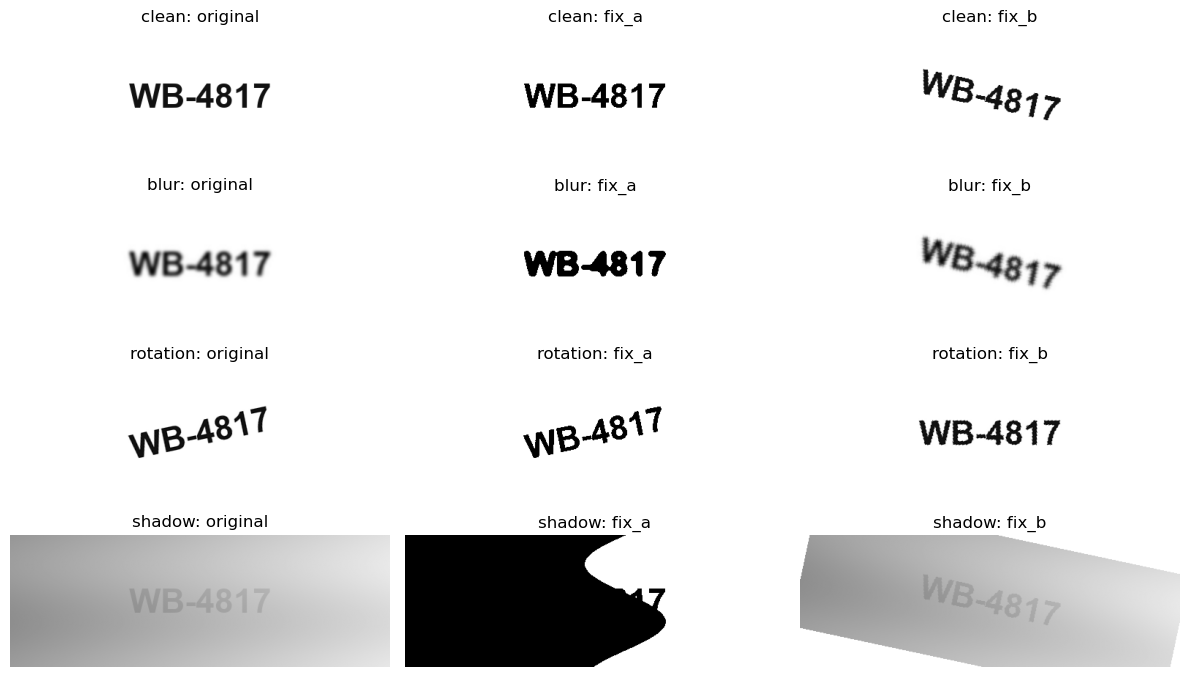

In [9]:
def fix_a(img):
    contrasted = ImageOps.autocontrast(img, cutoff=2)
    return contrasted.point(lambda pixel: 255 if pixel > 145 else 0)


def fix_b(img):
    return img.rotate(-12, expand=False, fillcolor=255)


fig, axes = plt.subplots(4, 3, figsize=(12, 7))
for i, condition in enumerate(CONDITIONS):
    filename = val_rows[val_rows["condition"] == condition].iloc[0]["filename"]
    original = load_image(filename)
    variants = [("original", original), ("fix_a", fix_a(original)),
                ("fix_b", fix_b(original))]
    for j, (title, image) in enumerate(variants):
        axes[i, j].imshow(image, cmap="gray", vmin=0, vmax=255)
        axes[i, j].set_title(f"{condition}: {title}")
        axes[i, j].axis("off")
plt.tight_layout()
plt.show()


In [10]:
val_a = run_system(val_rows, fix_a)
val_b = run_system(val_rows, fix_b)

for name, frame in [("baseline", val_base), ("fix_a", val_a), ("fix_b", val_b)]:
    print(name)
    display(report_table(frame))

trial_log = pd.DataFrame([
    {"system": name, **score(list(frame["norm_reference"]), list(frame["norm_prediction"]))}
    for name, frame in [("baseline", val_base), ("fix_a", val_a), ("fix_b", val_b)]
])
assert len(trial_log) == 3
display(trial_log)


baseline


,images,ref_chars,edits,corpus_CER,exact_match
condition,,,,,
clean,6,47,0,0.000,6/6 (100%)
blur,6,47,0,0.000,6/6 (100%)
rotation,6,47,43,0.915,0/6 (0%)
shadow,6,47,43,0.915,0/6 (0%)
ALL,24,188,86,0.457,12/24 (50%)


fix_a


,images,ref_chars,edits,corpus_CER,exact_match
condition,,,,,
clean,6,47,0,0.000,6/6 (100%)
blur,6,47,0,0.000,6/6 (100%)
rotation,6,47,32,0.681,0/6 (0%)
shadow,6,47,47,1.000,0/6 (0%)
ALL,24,188,79,0.420,12/24 (50%)


fix_b


,images,ref_chars,edits,corpus_CER,exact_match
condition,,,,,
clean,6,47,16,0.340,1/6 (17%)
blur,6,47,24,0.511,0/6 (0%)
rotation,6,47,0,0.000,6/6 (100%)
shadow,6,47,47,1.000,0/6 (0%)
ALL,24,188,87,0.463,7/24 (29%)


,system,images,chars,edits,cer,exact_n
0,baseline,24,188,86,0.457447,12
1,fix_a,24,188,79,0.420213,12
2,fix_b,24,188,87,0.462766,7


Validation trial log: baseline, fix_a, and fix_b were each run once. The selection rule is lowest validation corpus CER, with higher exact match as the tie-breaker.

In [11]:
candidates = [
    ("fix_a", val_a, fix_a,
     {"recipe": "fix_a", "autocontrast_cutoff": 2, "threshold": 145}),
    ("fix_b", val_b, fix_b,
     {"recipe": "fix_b", "rotation_degrees": -12, "expand": False}),
]


def selection_key(candidate):
    s = score(list(candidate[1]["norm_reference"]),
              list(candidate[1]["norm_prediction"]))
    return (s["cer"], -s["exact_n"])


chosen_name, chosen_val, chosen_fix, config = min(candidates, key=selection_key)
chosen_score = score(list(chosen_val["norm_reference"]),
                     list(chosen_val["norm_prediction"]))
config = dict(config)
config["validation_cer"] = chosen_score["cer"]
config["validation_exact_n"] = chosen_score["exact_n"]
CONFIG_PATH = OUTPUT_DIR / "chosen_config.json"


def freeze(config):
    """Write the choice once; verify it on a fresh-kernel rerun."""
    if CONFIG_PATH.exists():
        saved = json.loads(CONFIG_PATH.read_text(encoding="utf-8"))
        for key, value in config.items():
            assert saved[key] == value, f"Frozen configuration changed: {key}"
        print("Already frozen at", saved["frozen_at"])
        return saved
    saved = dict(config)
    saved["frozen_at"] = datetime.datetime.now().isoformat(timespec="seconds")
    CONFIG_PATH.write_text(json.dumps(saved, indent=2), encoding="utf-8")
    print("Frozen at", saved["frozen_at"])
    return saved


frozen_config = freeze(config)
print("Chosen recipe:", chosen_name)
print("Validation score:", chosen_score)


Frozen at 2026-11-07T02:56:20
Chosen recipe: fix_a
Validation score: {'images': 24, 'chars': 188, 'edits': 79, 'cer': 0.42021276595744683, 'exact_n': 12}


## Part 3.5 — Test once

The configuration has been frozen. Only now do we run OCR on the 24 test images, using the same OCR call and scoring for baseline and the chosen recipe.

In [12]:
assert CONFIG_PATH.exists(), "Freeze the recipe before test"
assert json.loads(CONFIG_PATH.read_text(encoding="utf-8"))["recipe"] == chosen_name

test_base = run_system(test_rows)
test_chosen = run_system(test_rows, chosen_fix)

print("Test baseline")
display(report_table(test_base))
print("Test", chosen_name)
display(report_table(test_chosen))

predictions = pd.concat([val_base, val_a, val_b, test_base, test_chosen],
                        ignore_index=True)
assert len(predictions) == 120
assert list(predictions.columns) == PRED_COLUMNS
assert len(predictions[predictions["split"] == "validation"]) == 72
assert len(predictions[predictions["split"] == "test"]) == 48
PRED_PATH = OUTPUT_DIR / "predictions.csv"
predictions.to_csv(PRED_PATH, index=False)
print("Saved", PRED_PATH)


Test baseline


,images,ref_chars,edits,corpus_CER,exact_match
condition,,,,,
clean,6,49,0,0.000,6/6 (100%)
blur,6,49,0,0.000,6/6 (100%)
rotation,6,49,22,0.449,0/6 (0%)
shadow,6,49,43,0.878,0/6 (0%)
ALL,24,196,65,0.332,12/24 (50%)


Test fix_a


,images,ref_chars,edits,corpus_CER,exact_match
condition,,,,,
clean,6,49,0,0.000,6/6 (100%)
blur,6,49,0,0.000,6/6 (100%)
rotation,6,49,26,0.531,0/6 (0%)
shadow,6,49,48,0.980,0/6 (0%)
ALL,24,196,74,0.378,12/24 (50%)


Saved /Users/alikhansagat/Desktop/Ali/DeepLearning/Home Works/10week/predictions.csv


## Part 4 — Evidence and recommendation

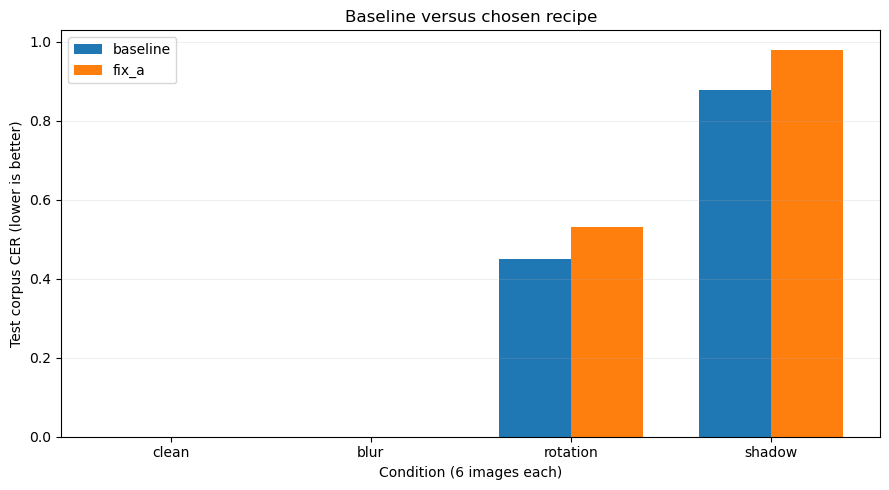

In [13]:
baseline_cer = []
chosen_cer = []
for condition in CONDITIONS:
    base_part = test_base[test_base["condition"] == condition]
    chosen_part = test_chosen[test_chosen["condition"] == condition]
    baseline_cer.append(score(list(base_part["norm_reference"]),
                              list(base_part["norm_prediction"]))["cer"])
    chosen_cer.append(score(list(chosen_part["norm_reference"]),
                            list(chosen_part["norm_prediction"]))["cer"])

x = list(range(len(CONDITIONS)))
width = 0.36
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar([i - width/2 for i in x], baseline_cer, width, label="baseline")
ax.bar([i + width/2 for i in x], chosen_cer, width, label=chosen_name)
ax.set_xticks(x, CONDITIONS)
ax.set_xlabel("Condition (6 images each)")
ax.set_ylabel("Test corpus CER (lower is better)")
ax.set_title("Baseline versus chosen recipe")
ax.legend()
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()


Improvement images/T04_rotation.png


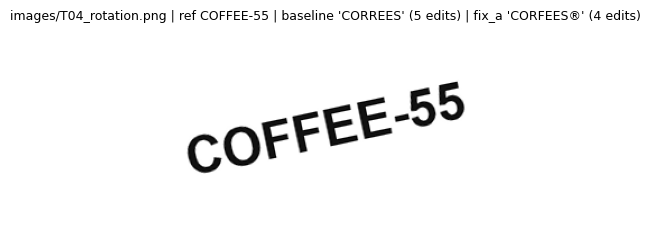

Unchanged images/T01_clean.png


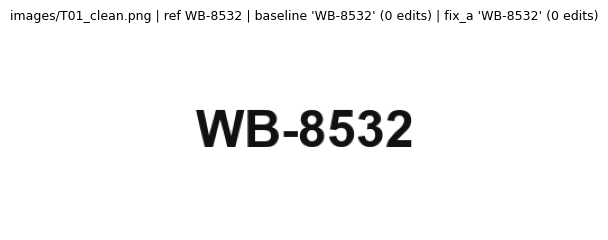

Regression images/T02_rotation.png


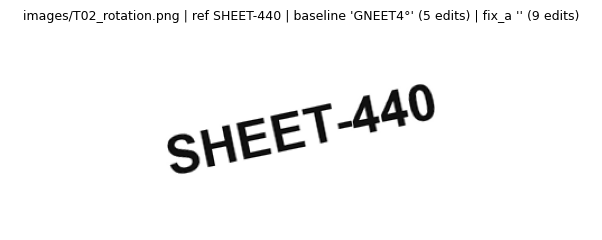

In [14]:
def show_example(filename, base_df, fix_df):
    base = base_df[base_df["filename"] == filename].iloc[0]
    fixed = fix_df[fix_df["filename"] == filename].iloc[0]
    fig, ax = plt.subplots(figsize=(9, 2.5))
    ax.imshow(load_image(filename), cmap="gray", vmin=0, vmax=255)
    ax.axis("off")
    ax.set_title(
        f'{filename} | ref {base["norm_reference"]} | '
        f'baseline {base["norm_prediction"]!r} ({base["edits"]} edits) | '
        f'{chosen_name} {fixed["norm_prediction"]!r} ({fixed["edits"]} edits)',
        fontsize=9,
    )
    plt.tight_layout()
    plt.show()


comparison = test_base[["filename", "norm_reference", "norm_prediction", "edits"]].merge(
    test_chosen[["filename", "norm_prediction", "edits"]],
    on="filename", suffixes=("_base", "_fix"),
)
comparison["delta_edits"] = comparison["edits_fix"] - comparison["edits_base"]

for label, subset in [
    ("Improvement", comparison[comparison["delta_edits"] < 0]),
    ("Unchanged", comparison[comparison["delta_edits"] == 0]),
    ("Regression", comparison[comparison["delta_edits"] > 0]),
]:
    if subset.empty:
        print(label, "does not occur in the test set")
    else:
        filename = subset.iloc[0]["filename"]
        print(label, filename)
        show_example(filename, test_base, test_chosen)


**Improvement — T04_rotation.png.** The image shows a slanted but still legible COFFEE-55 label. Baseline read `CORREES` (5 edits) and fix_a read `CORFEES®` (4 edits); I suspect thresholding preserved one more letter shape, although neither output is a correct code.

**Unchanged — T01_clean.png.** The label WB-8532 is level, dark, and clear against a white background. Both systems read it exactly, so the extra contrast and threshold step did not change this already easy case.

**Regression — T02_rotation.png.** The SHEET-440 line is slanted, while its letters remain visually clear to a person. Baseline produced `GNEET4°` (5 edits), but fix_a returned an empty string (9 edits); I suspect the threshold step damaged the slanted strokes enough that Tesseract could not recover a text line.

I would keep the baseline for this small test rather than deploy fix_a as an automatic preprocessing recipe. The required selection rule chose fix_a on validation: its corpus CER was 0.420, compared with 0.457 for baseline. On test, however, fix_a increased CER from 0.332 to 0.378, while exact match stayed at 12 of 24 images. I would report this regression without changing the frozen configuration. Shadow needs the most work: fix_a reached 0.980 CER there, and predictions were often short fragments or empty. These 48 synthetic images use one font, one script, and already cropped single-line labels. They cannot show performance across real customer photos, other fonts, complex lighting and backgrounds, or missed text regions in full photographs.

**Exact match:** A product code with even one wrong character may identify a different product or fail a database lookup, so a small CER does not guarantee a usable code.

**Detection:** Every test image already contains a cropped text line. The experiment only measures reading that crop; it cannot tell whether a detector would find the label in a full photograph.

## Sources

- Week 9 lecture slides (course material, if available).
- Hannun, *Sequence Modeling with CTC* (2017): https://distill.pub/2017/ctc/
- Tesseract documentation, *Improving the quality of the output*: https://tesseract-ocr.github.io/tessdoc/ImproveQuality.html
- Shi, Bai, Yao, *An End-to-End Trainable Neural Network for Image-based Sequence Recognition* (2015): https://arxiv.org/abs/1507.05717
- RapidFuzz Levenshtein documentation: https://rapidfuzz.github.io/RapidFuzz/Usage/distance/Levenshtein.html